In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Data Science Main/Main Project 2/UNSW_NB15_training-set.csv')

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (175341, 45)


In [ ]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_df = missing_df.sort_values(
    by='Missing Values',
    ascending=False
)

missing_df

,Missing Values,Missing Percentage
id,0,0.0
dur,0,0.0
proto,0,0.0
service,0,0.0
state,0,0.0
spkts,0,0.0
dpkts,0,0.0
sbytes,0,0.0
dbytes,0,0.0
rate,0,0.0


In [ ]:
dash_count = (df == '-').sum()

dash_percentage = (dash_count / len(df)) * 100

dash_df = pd.DataFrame({
    'Dash Count': dash_count,
    'Dash Percentage': dash_percentage
})

dash_df = dash_df.sort_values(
    by='Dash Count',
    ascending=False
)

dash_df

,Dash Count,Dash Percentage
service,94168,53.705636
id,0,0.000000
dur,0,0.000000
proto,0,0.000000
state,0,0.000000
spkts,0,0.000000
dpkts,0,0.000000
sbytes,0,0.000000
dbytes,0,0.000000
rate,0,0.000000


In [ ]:
question_count = (df == '?').sum()

question_percentage = (question_count / len(df)) * 100

question_df = pd.DataFrame({
    'Question Mark Count': question_count,
    'Question Mark Percentage': question_percentage
})

question_df = question_df.sort_values(
    by='Question Mark Count',
    ascending=False
)

question_df

,Question Mark Count,Question Mark Percentage
id,0,0.0
dur,0,0.0
proto,0,0.0
service,0,0.0
state,0,0.0
spkts,0,0.0
dpkts,0,0.0
sbytes,0,0.0
dbytes,0,0.0
rate,0,0.0


In [ ]:
missing_analysis = pd.DataFrame({
    'NaN': df.isnull().sum(),
    '-': (df == '-').sum(),
    '?': (df == '?').sum()
})

missing_analysis['Total Missing'] = (
    missing_analysis['NaN'] +
    missing_analysis['-'] +
    missing_analysis['?']
)

missing_analysis['Missing %'] = (
    missing_analysis['Total Missing'] / len(df) * 100
)

missing_analysis.sort_values(
    by='Total Missing',
    ascending=False
)

,NaN,-,?,Total Missing,Missing %
service,0,94168,0,94168,53.705636
id,0,0,0,0,0.000000
dur,0,0,0,0,0.000000
proto,0,0,0,0,0.000000
state,0,0,0,0,0.000000
spkts,0,0,0,0,0.000000
dpkts,0,0,0,0,0.000000
sbytes,0,0,0,0,0.000000
dbytes,0,0,0,0,0.000000
rate,0,0,0,0,0.000000


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

Number of numerical columns: 41
Number of categorical columns: 4


In [ ]:
print("Numerical columns:\n")

for col in numerical_cols:
    print(col)

Numerical columns:

id
dur
spkts
dpkts
sbytes
dbytes
rate
sttl
dttl
sload
dload
sloss
dloss
sinpkt
dinpkt
sjit
djit
swin
stcpb
dtcpb
dwin
tcprtt
synack
ackdat
smean
dmean
trans_depth
response_body_len
ct_srv_src
ct_state_ttl
ct_dst_ltm
ct_src_dport_ltm
ct_dst_sport_ltm
ct_dst_src_ltm
is_ftp_login
ct_ftp_cmd
ct_flw_http_mthd
ct_src_ltm
ct_srv_dst
is_sm_ips_ports
label


In [ ]:
print("\nCategorical columns:\n")

for col in categorical_cols:
    print(col)


Categorical columns:

proto
service
state
attack_cat


In [ ]:
unique_df = pd.DataFrame({
    'Column': df.columns,
    'Unique Values': [
        df[col].nunique()
        for col in df.columns
    ]
})

unique_df

,Column,Unique Values
0,id,175341
1,dur,74039
2,proto,133
3,service,13
4,state,9
5,spkts,480
6,dpkts,443
7,sbytes,7214
8,dbytes,6660
9,rate,76991


In [ ]:
print(df['label'].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64


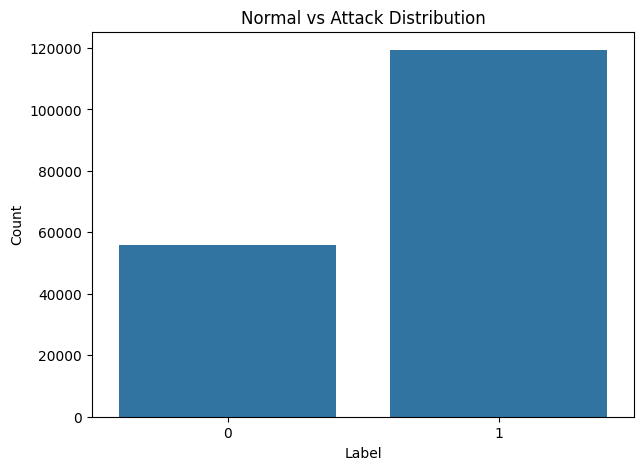

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label'
)

plt.title('Normal vs Attack Distribution')
plt.xlabel('Label')
plt.ylabel('Count')

plt.show()

In [ ]:
print(df['attack_cat'].value_counts(dropna=False))

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [ ]:
attack_distribution = (
    df['attack_cat']
    .value_counts(dropna=False)
)

attack_percentage = (
    df['attack_cat']
    .value_counts(normalize=True, dropna=False) * 100
)

attack_analysis = pd.DataFrame({
    'Count': attack_distribution,
    'Percentage': attack_percentage
})

attack_analysis

,Count,Percentage
attack_cat,,
Normal,56000,31.937767
Generic,40000,22.812691
Exploits,33393,19.044605
Fuzzers,18184,10.370649
DoS,12264,6.994371
Reconnaissance,10491,5.983198
Analysis,2000,1.140635
Backdoor,1746,0.995774
Shellcode,1133,0.646169


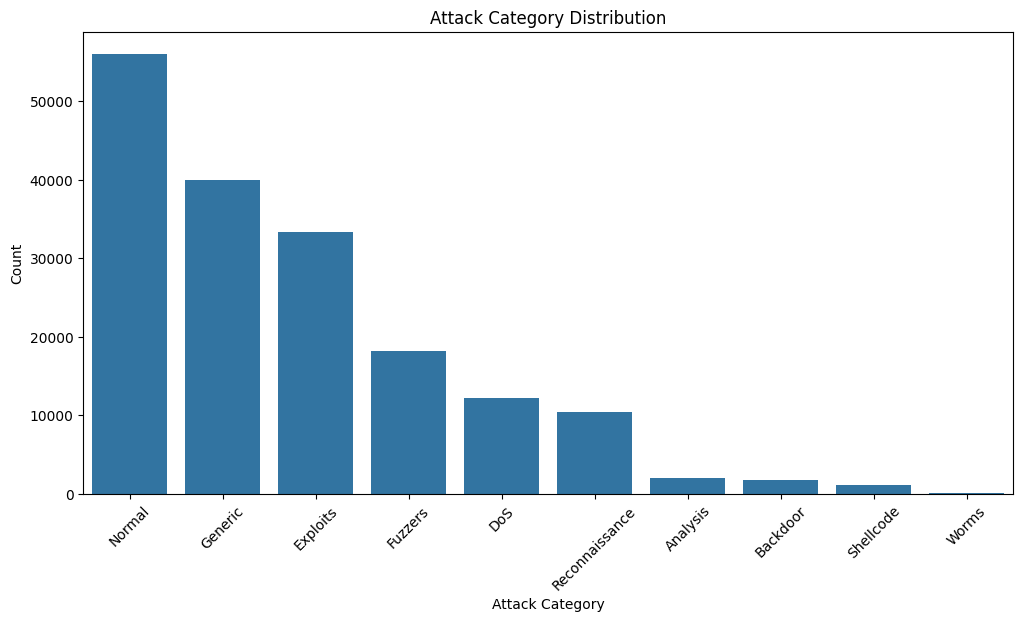

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='attack_cat',
    order=df['attack_cat'].value_counts().index
)

plt.title('Attack Category Distribution')
plt.xlabel('Attack Category')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

In [ ]:
label_correlation = df.corr(numeric_only=True)['label'].drop('label')

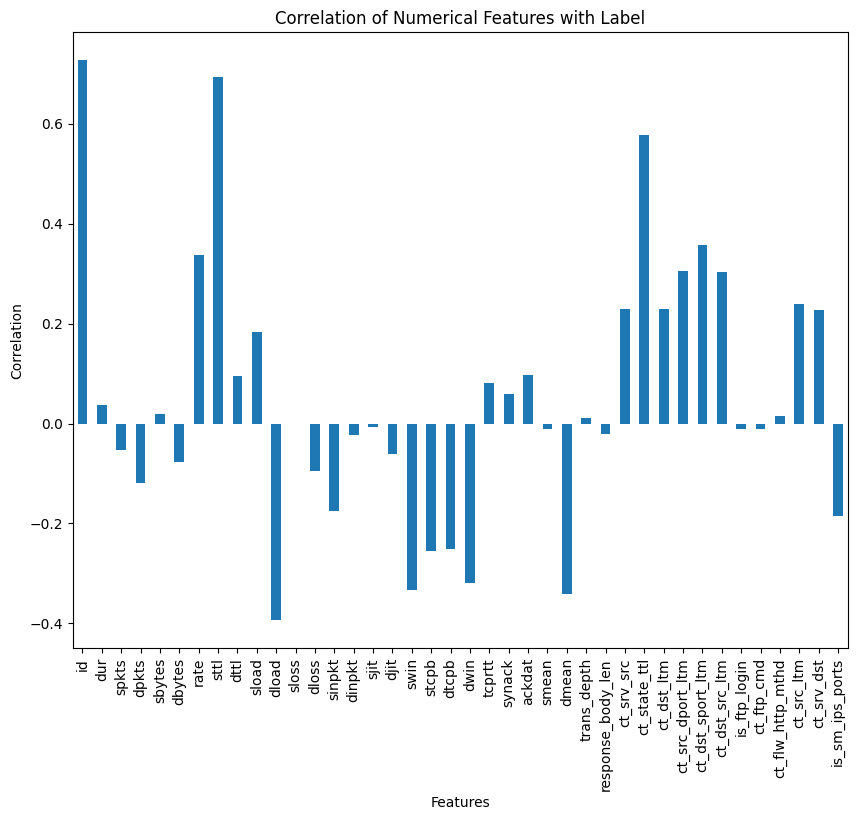

In [ ]:
plt.figure(figsize=(10, 8))

label_correlation.plot(
    kind='bar'
)

plt.title('Correlation of Numerical Features with Label')
plt.xlabel('Features')
plt.ylabel('Correlation')

plt.xticks(rotation=90)

plt.show()

In [ ]:
feature_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing NaN': df.isnull().sum(),
    'Missing -': (df == '-').sum(),
    'Missing ?': (df == '?').sum(),
    'Missing Total': (
        df.isnull().sum() +
        (df == '-').sum() +
        (df == '?').sum()
    )
})

feature_summary

,Data Type,Unique Values,Missing NaN,Missing -,Missing ?,Missing Total
id,int64,175341,0,0,0,0
dur,float64,74039,0,0,0,0
proto,object,133,0,0,0,0
service,object,13,0,94168,0,94168
state,object,9,0,0,0,0
spkts,int64,480,0,0,0,0
dpkts,int64,443,0,0,0,0
sbytes,int64,7214,0,0,0,0
dbytes,int64,6660,0,0,0,0
rate,float64,76991,0,0,0,0


In [ ]:
df['service'].replace('-', 'Unknown', inplace=True)
print(df['service'].value_counts().head(15))

/tmp/ipykernel_433/2263652467.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['service'].replace('-', 'Unknown', inplace=True)


service
Unknown     94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64


In [ ]:
df.drop(columns=['id'], inplace=True)

In [ ]:
print(df.shape)
print(df.columns)

(175341, 44)
Index(['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='object')


In [ ]:
X = df.drop(columns=['label', 'attack_cat'])

y = df[['label', 'attack_cat']]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y['label']
)

In [ ]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Targets:", y_train.shape)
print("Testing Targets:", y_test.shape)

Training Features: (140272, 42)
Testing Features: (35069, 42)
Training Targets: (140272, 2)
Testing Targets: (35069, 2)


In [ ]:
print("Training Distribution:")
print(y_train['label'].value_counts())

print("\nTesting Distribution:")
print(y_test['label'].value_counts())

Training Distribution:
label
1    95472
0    44800
Name: count, dtype: int64

Testing Distribution:
label
1    23869
0    11200
Name: count, dtype: int64


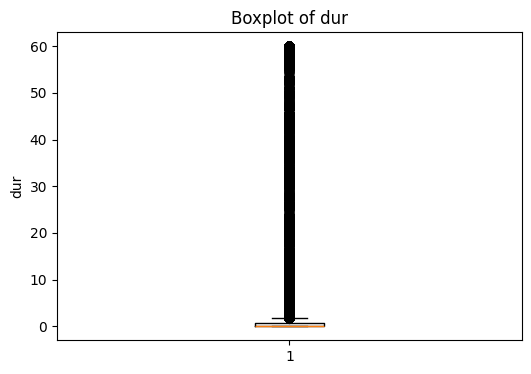

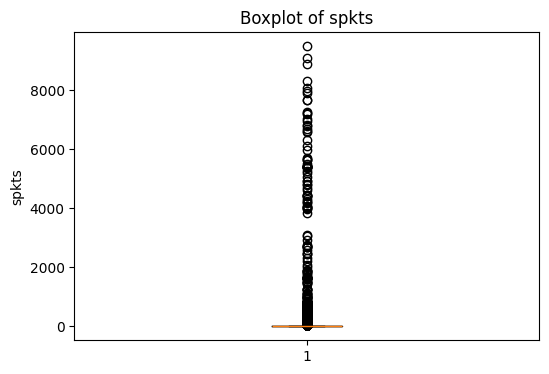

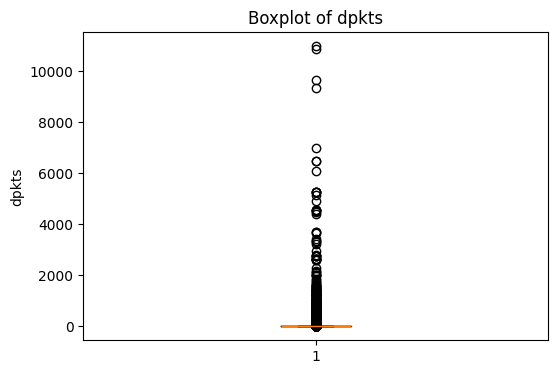

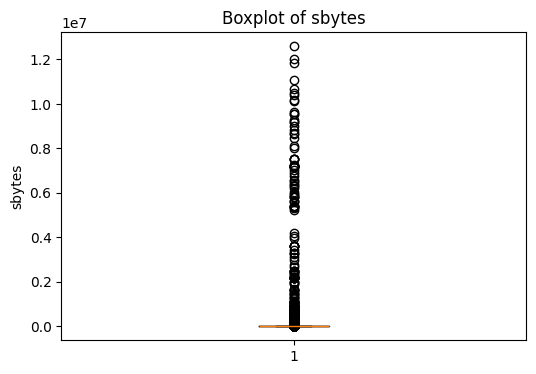

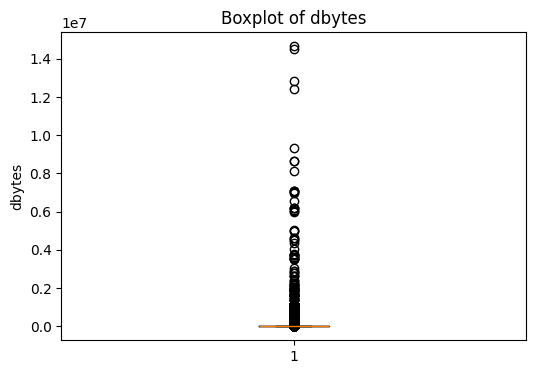

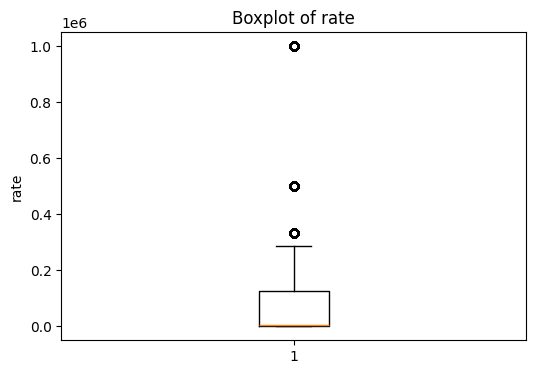

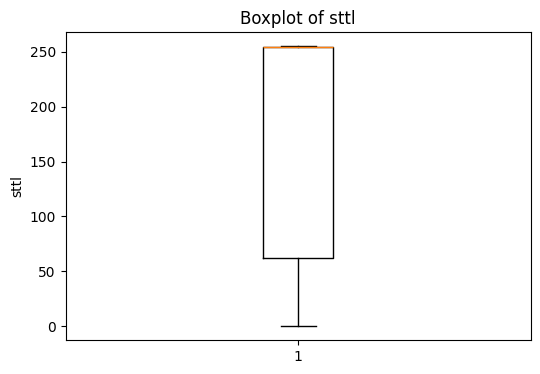

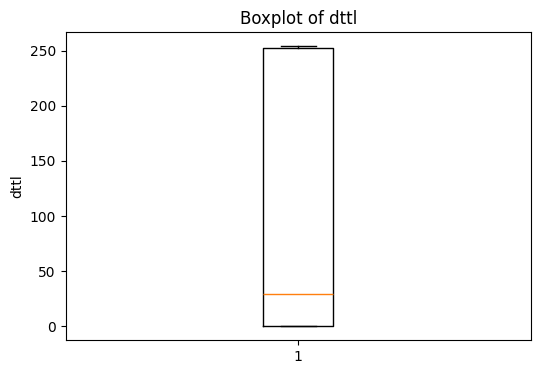

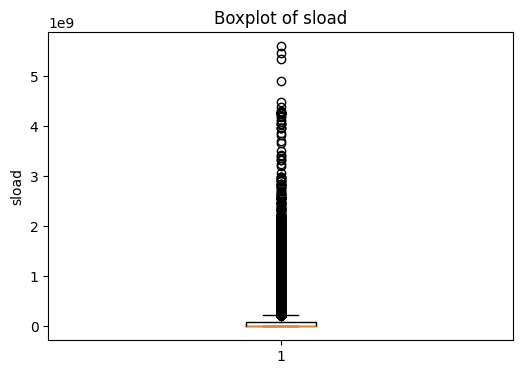

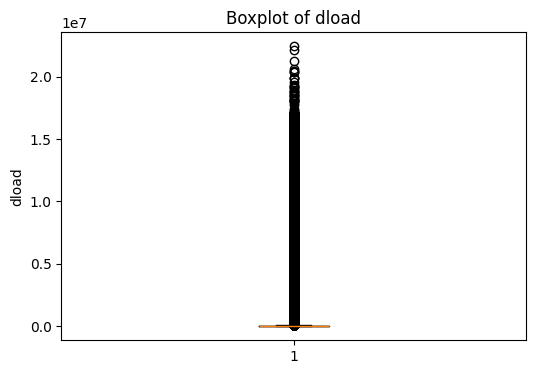

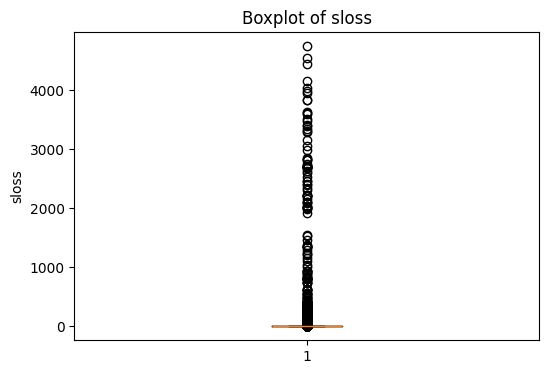

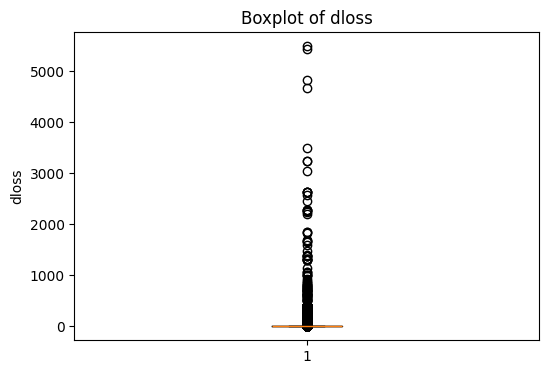

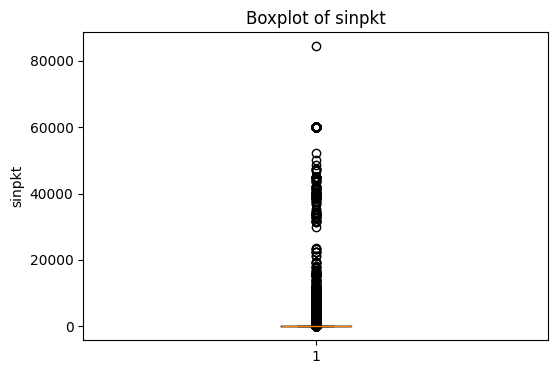

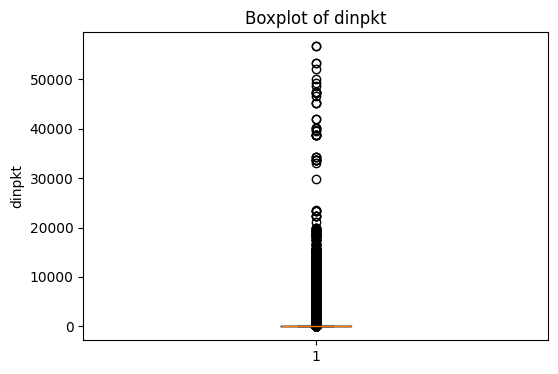

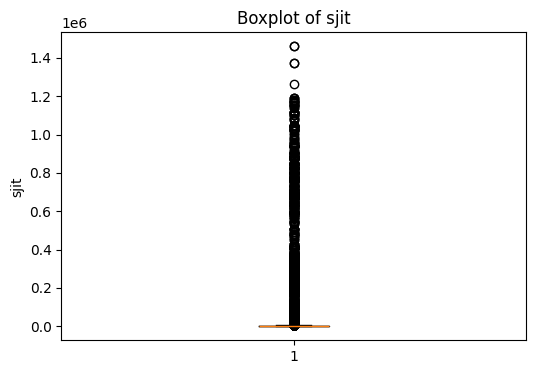

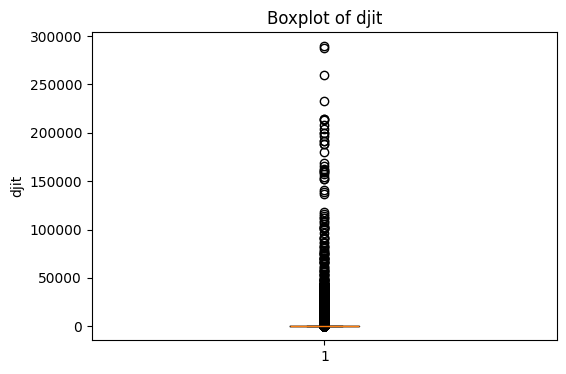

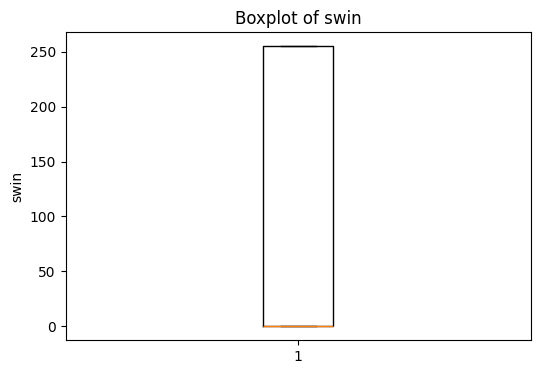

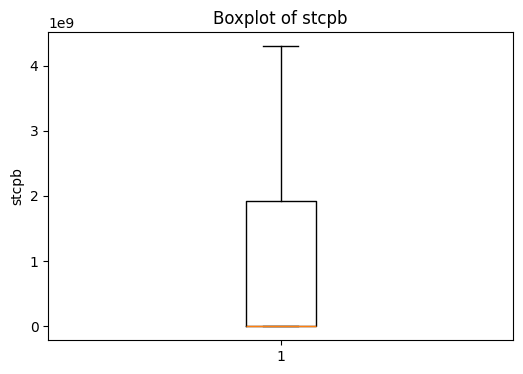

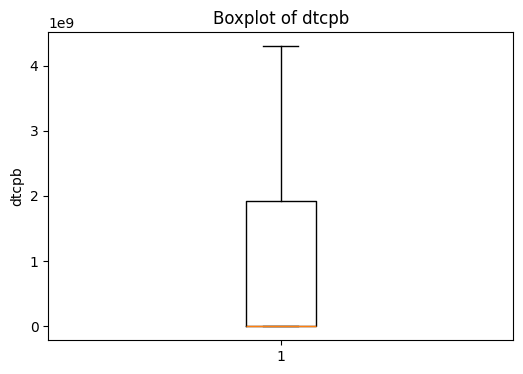

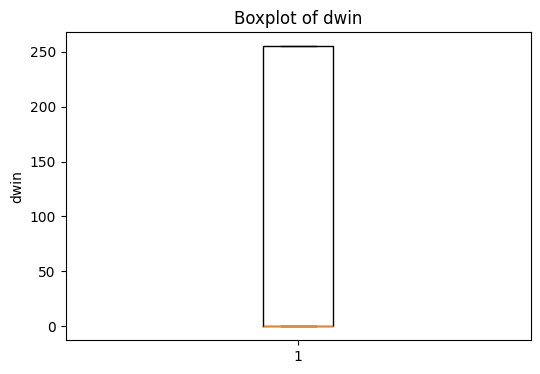

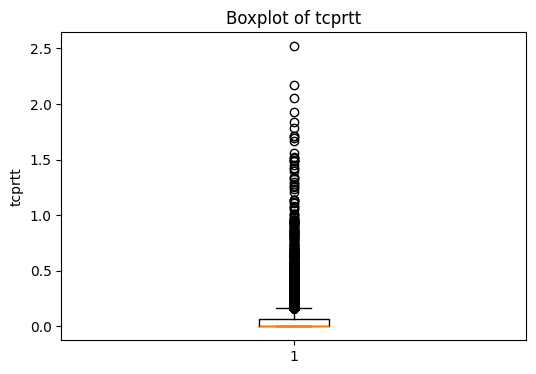

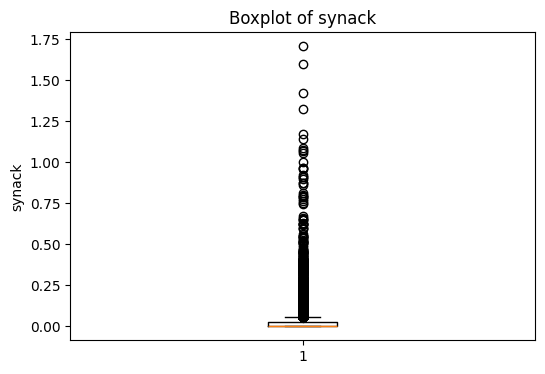

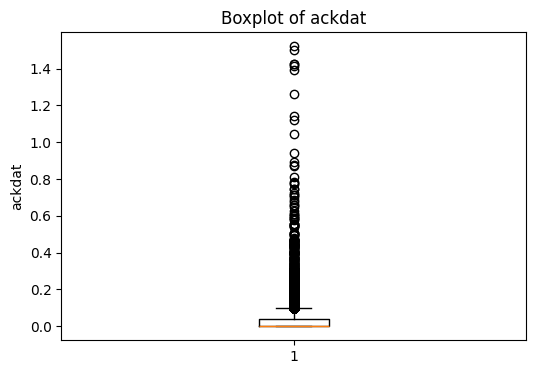

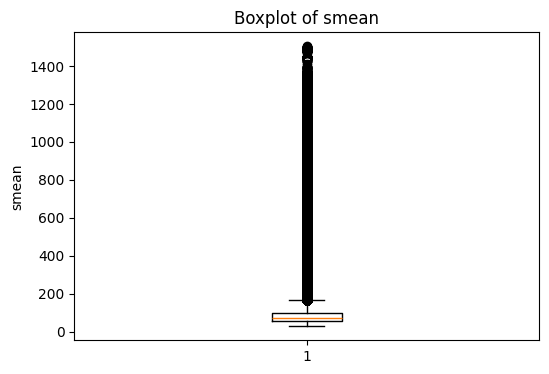

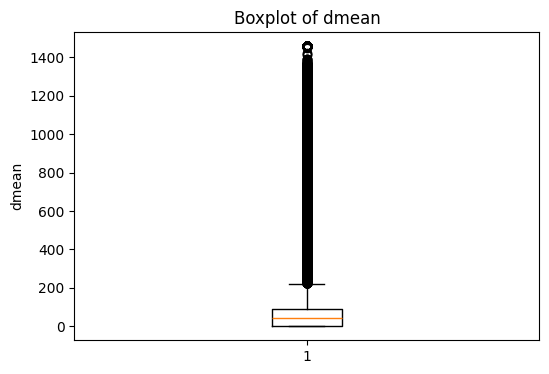

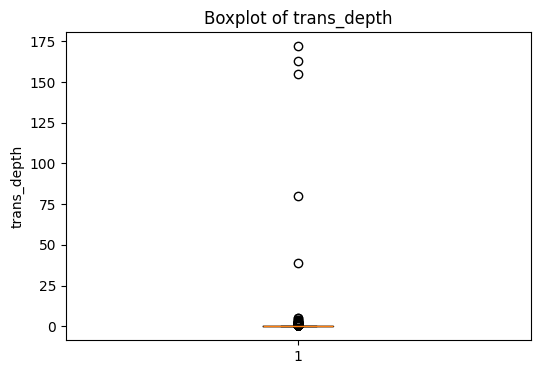

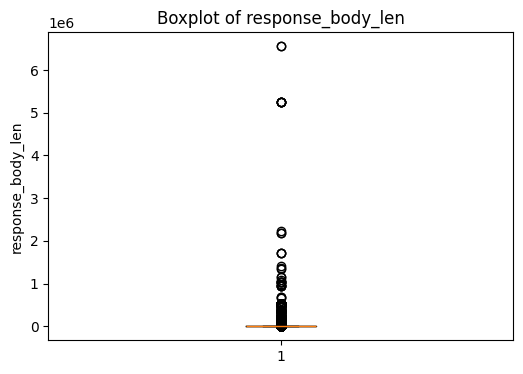

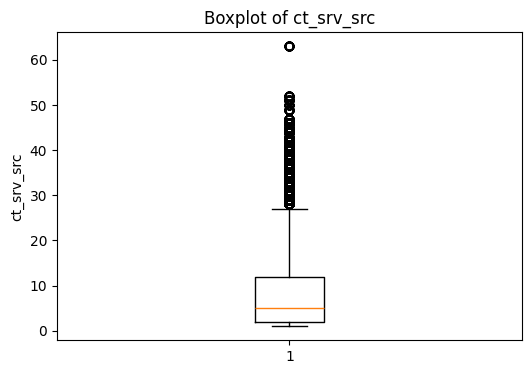

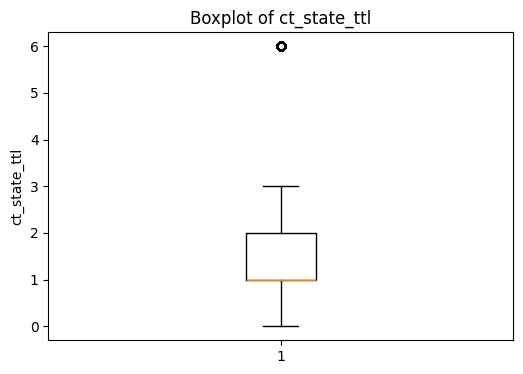

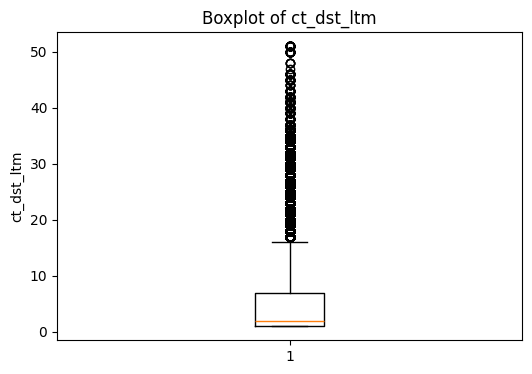

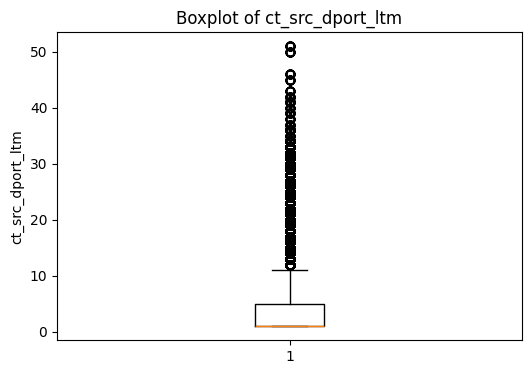

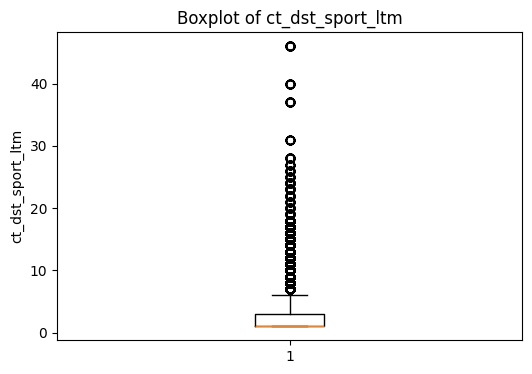

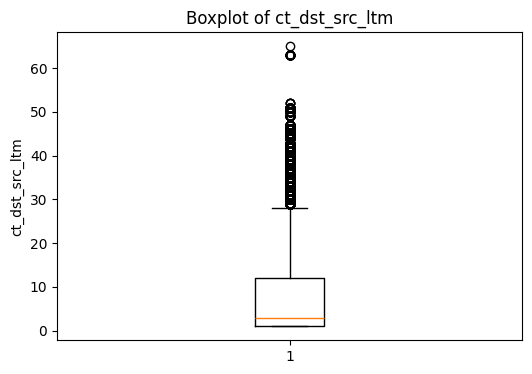

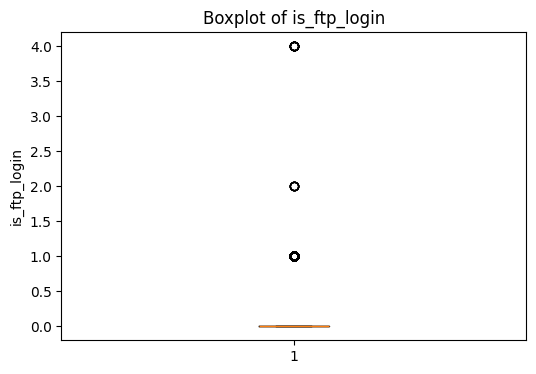

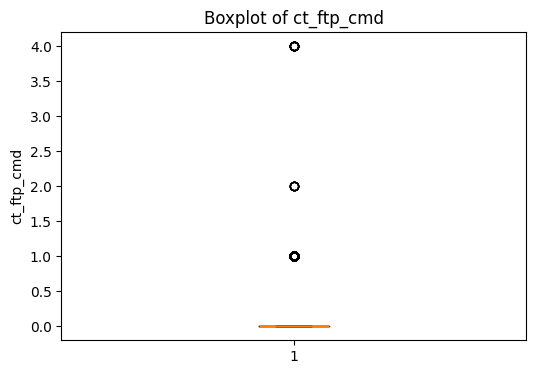

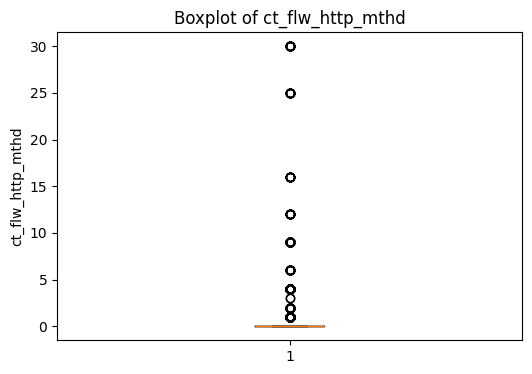

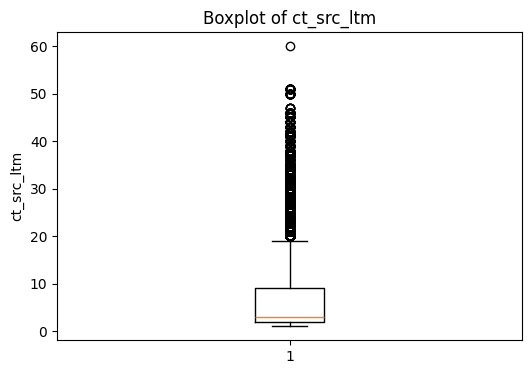

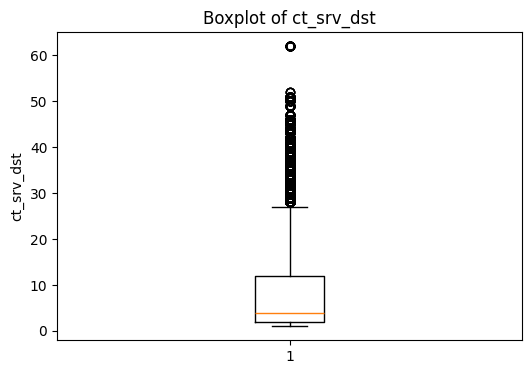

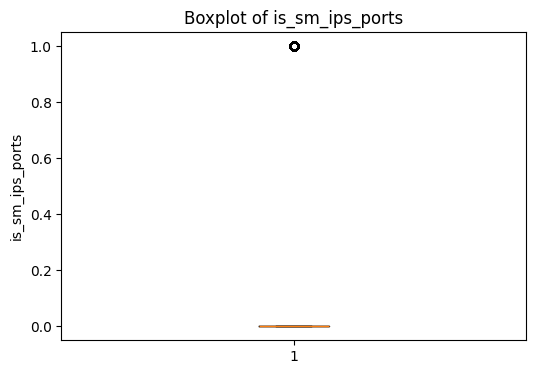

In [ ]:
import matplotlib.pyplot as plt

# Select numerical columns from training features
columns = X_train.select_dtypes(include=['number']).columns

# Plot boxplots
for i in columns:
    plt.figure(figsize=(6, 4))
    plt.boxplot(X_train[i].dropna())
    plt.title(f'Boxplot of {i}')
    plt.ylabel(i)
    plt.show()

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
X_train_fs = pd.get_dummies(
    X_train,
    columns=['proto', 'service', 'state'],
    dtype=int
)

In [ ]:
print("Original features:", X_train.shape[1])
print("Encoded features:", X_train_fs.shape[1])

Original features: 42
Encoded features: 192


In [ ]:
fs_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

fs_model.fit(X_train_fs, y_train['label'])

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
importance_df = pd.DataFrame({
    'Feature': X_train_fs.columns,
    'Importance': fs_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

              Feature  Importance
6                sttl    0.647837
37         ct_srv_dst    0.046662
3              sbytes    0.031463
31   ct_dst_sport_ltm    0.023676
23              smean    0.019531
10              sloss    0.014828
2               dpkts    0.013099
32     ct_dst_src_ltm    0.013022
159        proto_unas    0.012439
24              dmean    0.011742
185         state_CON    0.011740
16               swin    0.011676
177      service_http    0.010526
21             synack    0.009969
158         proto_udp    0.009422
188         state_INT    0.008416
27         ct_srv_src    0.007928
4              dbytes    0.007844
174       service_dns    0.007532
28       ct_state_ttl    0.007180


In [ ]:
original_features = X_train.columns

grouped_importance = {}

for feature in original_features:

    if feature in ['proto', 'service', 'state']:

        encoded_columns = [
            col for col in X_train_fs.columns
            if col.startswith(feature + '_')
        ]

        grouped_importance[feature] = importance_df[
            importance_df['Feature'].isin(encoded_columns)
        ]['Importance'].sum()

    else:
        grouped_importance[feature] = importance_df.loc[
            importance_df['Feature'] == feature,
            'Importance'
        ].sum()

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': grouped_importance.keys(),
    'Importance': grouped_importance.values()
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print(feature_importance)

              Feature  Importance
0                sttl    0.647837
1          ct_srv_dst    0.046662
2              sbytes    0.031463
3               proto    0.030390
4             service    0.027927
5    ct_dst_sport_ltm    0.023676
6               state    0.020674
7               smean    0.019531
8               sloss    0.014828
9               dpkts    0.013099
10     ct_dst_src_ltm    0.013022
11              dmean    0.011742
12               swin    0.011676
13             synack    0.009969
14         ct_srv_src    0.007928
15             dbytes    0.007844
16       ct_state_ttl    0.007180
17        trans_depth    0.006508
18              dloss    0.005197
19             tcprtt    0.005164
20   ct_flw_http_mthd    0.004832
21             sinpkt    0.003848
22   ct_src_dport_ltm    0.003463
23              spkts    0.003374
24  response_body_len    0.003112
25               djit    0.002807
26                dur    0.002470
27         ct_dst_ltm    0.002401
28         ct_

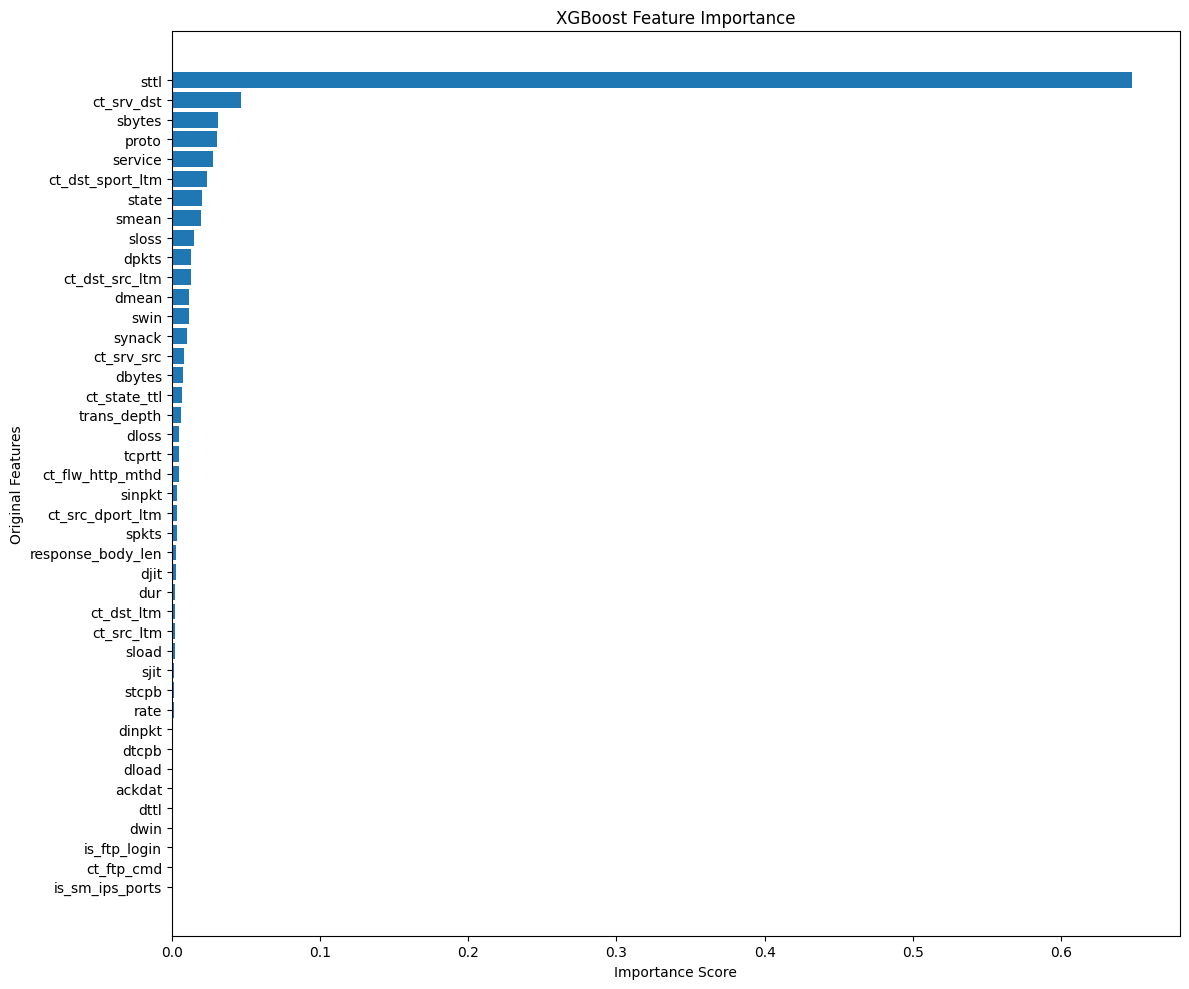

In [ ]:
plt.figure(figsize=(12, 10))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.gca().invert_yaxis()

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Original Features')

plt.tight_layout()
plt.show()

In [ ]:
# Select the top 17 original features
selected_features = feature_importance.head(17)['Feature'].tolist()

print("Selected Feature Count:", len(selected_features))

print("\nFinal Selected Features:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

Selected Feature Count: 17

Final Selected Features:
1. sttl
2. ct_srv_dst
3. sbytes
4. proto
5. service
6. ct_dst_sport_ltm
7. state
8. smean
9. sloss
10. dpkts
11. ct_dst_src_ltm
12. dmean
13. swin
14. synack
15. ct_srv_src
16. dbytes
17. ct_state_ttl


In [ ]:
selected_features = feature_importance.head(17)['Feature'].tolist()

print(selected_features)

['sttl', 'ct_srv_dst', 'sbytes', 'proto', 'service', 'ct_dst_sport_ltm', 'state', 'smean', 'sloss', 'dpkts', 'ct_dst_src_ltm', 'dmean', 'swin', 'synack', 'ct_srv_src', 'dbytes', 'ct_state_ttl']


In [ ]:
import joblib

joblib.dump(selected_features, 'selected_features.pkl')

['selected_features.pkl']

In [ ]:
categorical_features = [
    col for col in selected_features
    if col in ['proto', 'service', 'state']
]

numerical_features = [
    col for col in selected_features
    if col not in categorical_features
]

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['proto', 'service', 'state']
Numerical Features: ['sttl', 'ct_srv_dst', 'sbytes', 'ct_dst_sport_ltm', 'smean', 'sloss', 'dpkts', 'ct_dst_src_ltm', 'dmean', 'swin', 'synack', 'ct_srv_src', 'dbytes', 'ct_state_ttl']


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore')

X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)

X_test_encoded = encoder.transform(
    X_test[categorical_features]
)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numerical_features]
)

X_test_scaled = scaler.transform(
    X_test[numerical_features]
)

In [ ]:
import numpy as np

X_train_processed = np.hstack([
    X_train_scaled,
    X_train_encoded.toarray()
])

X_test_processed = np.hstack([
    X_test_scaled,
    X_test_encoded.toarray()
])

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (140272, 167)
Testing Shape: (35069, 167)


In [ ]:
import joblib

preprocessor = {
    'selected_features': selected_features,
    'categorical_features': categorical_features,
    'numerical_features': numerical_features,
    'encoder': encoder,
    'scaler': scaler
}

joblib.dump(preprocessor, 'preprocessor.pkl')

print("Preprocessing file saved successfully!")

Preprocessing file saved successfully!


In [ ]:
from google.colab import files

files.download('preprocessor.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(y_train['label'].value_counts())

label
1    95472
0    44800
Name: count, dtype: int64


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_balanced, y_train_balanced = rus.fit_resample(
    X_train_processed,
    y_train['label']
)

In [ ]:
print("Before Undersampling:")
print(y_train['label'].value_counts())

print("\nAfter Undersampling:")
print(y_train_balanced.value_counts())

Before Undersampling:
label
1    95472
0    44800
Name: count, dtype: int64

After Undersampling:
label
0    44800
1    44800
Name: count, dtype: int64


In [ ]:
print("Original Training Shape:", X_train_processed.shape)
print("Balanced Training Shape:", X_train_balanced.shape)

print("Testing Shape:", X_test_processed.shape)

Original Training Shape: (140272, 167)
Balanced Training Shape: (89600, 167)
Testing Shape: (35069, 167)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train
lr_model.fit(X_train_balanced, y_train_balanced)

# Predict
y_pred = lr_model.predict(X_test_processed)
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
print("LOGISTIC REGRESSION - MODEL 1")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test['label'], y_pred))
print("Precision:", precision_score(y_test['label'], y_pred))
print("Recall   :", recall_score(y_test['label'], y_pred))
print("F1 Score :", f1_score(y_test['label'], y_pred))
print("ROC-AUC  :", roc_auc_score(y_test['label'], y_prob))

print("\nClassification Report:")
print(classification_report(
    y_test['label'],
    y_pred,
    target_names=['Normal', 'Attack']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test['label'], y_pred))

LOGISTIC REGRESSION - MODEL 1
--------------------------------
Accuracy : 0.9311072457155892
Precision: 0.9400254338105591
Recall   : 0.9600318404625247
F1 Score : 0.9499233097044315
ROC-AUC  : 0.979848026504791

Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.87      0.89     11200
      Attack       0.94      0.96      0.95     23869

    accuracy                           0.93     35069
   macro avg       0.93      0.91      0.92     35069
weighted avg       0.93      0.93      0.93     35069

Confusion Matrix:
[[ 9738  1462]
 [  954 22915]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=None,
    random_state=42
)

# Train model
dt_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_dt = dt_model.predict(X_test_processed)
y_prob_dt = dt_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
print("DECISION TREE - MODEL 1")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test['label'], y_pred_dt))
print("Precision:", precision_score(y_test['label'], y_pred_dt))
print("Recall   :", recall_score(y_test['label'], y_pred_dt))
print("F1 Score :", f1_score(y_test['label'], y_pred_dt))
print("ROC-AUC  :", roc_auc_score(y_test['label'], y_prob_dt))

print("\nClassification Report:")
print(classification_report(
    y_test['label'],
    y_pred_dt,
    target_names=['Normal', 'Attack']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test['label'], y_pred_dt))

DECISION TREE - MODEL 1
--------------------------------
Accuracy : 0.9427699677778094
Precision: 0.9758401532300192
Recall   : 0.9391679584398174
F1 Score : 0.9571529215857902
ROC-AUC  : 0.9497570687173441

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.95      0.91     11200
      Attack       0.98      0.94      0.96     23869

    accuracy                           0.94     35069
   macro avg       0.93      0.94      0.94     35069
weighted avg       0.95      0.94      0.94     35069

Confusion Matrix:
[[10645   555]
 [ 1452 22417]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
print("RANDOM FOREST - MODEL 1")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test['label'], y_pred_rf))
print("Precision:", precision_score(y_test['label'], y_pred_rf))
print("Recall   :", recall_score(y_test['label'], y_pred_rf))
print("F1 Score :", f1_score(y_test['label'], y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test['label'], y_prob_rf))

print("\nClassification Report:")
print(classification_report(
    y_test['label'],
    y_pred_rf,
    target_names=['Normal', 'Attack']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test['label'], y_pred_rf))

RANDOM FOREST - MODEL 1
--------------------------------
Accuracy : 0.9520659271721463
Precision: 0.9804677349501949
Recall   : 0.9484687251246386
F1 Score : 0.9642028152217892
ROC-AUC  : 0.9929792528264396

Classification Report:
              precision    recall  f1-score   support

      Normal       0.90      0.96      0.93     11200
      Attack       0.98      0.95      0.96     23869

    accuracy                           0.95     35069
   macro avg       0.94      0.95      0.95     35069
weighted avg       0.95      0.95      0.95     35069

Confusion Matrix:
[[10749   451]
 [ 1230 22639]]


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
print("XGBOOST - MODEL 1")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_test['label'], y_pred_xgb))
print("Precision:", precision_score(y_test['label'], y_pred_xgb))
print("Recall   :", recall_score(y_test['label'], y_pred_xgb))
print("F1 Score :", f1_score(y_test['label'], y_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_test['label'], y_prob_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test['label'],
    y_pred_xgb,
    target_names=['Normal', 'Attack']
))

print("Confusion Matrix:")
print(confusion_matrix(y_test['label'], y_pred_xgb))


XGBOOST - MODEL 1
--------------------------------
Accuracy : 0.9427414525649433
Precision: 0.9792187294489018
Recall   : 0.9357325401147932
F1 Score : 0.9569818758301555
ROC-AUC  : 0.9921486177528533

Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.96      0.91     11200
      Attack       0.98      0.94      0.96     23869

    accuracy                           0.94     35069
   macro avg       0.93      0.95      0.94     35069
weighted avg       0.95      0.94      0.94     35069

Confusion Matrix:
[[10726   474]
 [ 1534 22335]]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# 1. Base XGBoost model
xgb_base = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# 2. Hyperparameter search space
param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [1, 2, 5, 10]
}

# 3. Randomized Search
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=10,
    scoring='recall',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# 4. Train using balanced training data
random_search.fit(
    X_train_balanced,
    y_train_balanced
)

# 5. Display results
print("\nTUNING COMPLETED")

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest CV Recall:")
print(random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

TUNING COMPLETED

Best Parameters:
{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}

Best CV Recall:
0.9462722864985796


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Get best tuned model
xgb_tuned = random_search.best_estimator_

# Predictions
y_pred_tuned = xgb_tuned.predict(X_test_processed)
y_prob_tuned = xgb_tuned.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
print("TUNED XGBOOST - MODEL 1")
print(f"Accuracy  : {accuracy_score(y_test['label'], y_pred_tuned):.4f}")
print(f"Precision : {precision_score(y_test['label'], y_pred_tuned):.4f}")
print(f"Recall    : {recall_score(y_test['label'], y_pred_tuned):.4f}")
print(f"F1 Score  : {f1_score(y_test['label'], y_pred_tuned):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test['label'], y_prob_tuned):.4f}")

TUNED XGBOOST - MODEL 1
Accuracy  : 0.9512
Precision : 0.9801
Recall    : 0.9476
F1 Score  : 0.9636
ROC-AUC   : 0.9937
TUNED XGBOOST - MODEL 1
Accuracy  : 0.9512
Precision : 0.9801
Recall    : 0.9476
F1 Score  : 0.9636
ROC-AUC   : 0.9937
TUNED XGBOOST - MODEL 1
Accuracy  : 0.9512
Precision : 0.9801
Recall    : 0.9476
F1 Score  : 0.9636
ROC-AUC   : 0.9937


In [ ]:
import joblib
joblib.dump(xgb_tuned, 'xgboost_tuned_model.pkl')
print("Tuned XGBoost model saved successfully!")

Tuned XGBoost model saved successfully!
Tuned XGBoost model saved successfully!
Tuned XGBoost model saved successfully!


In [ ]:
from google.colab import files
files.download('xgboost_tuned_model.pkl')

**MODEL 2**

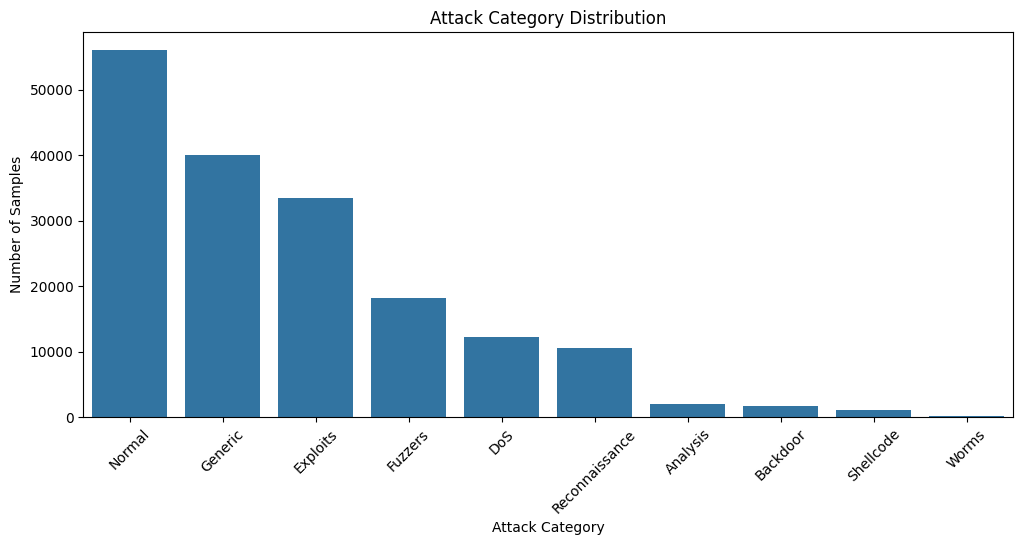

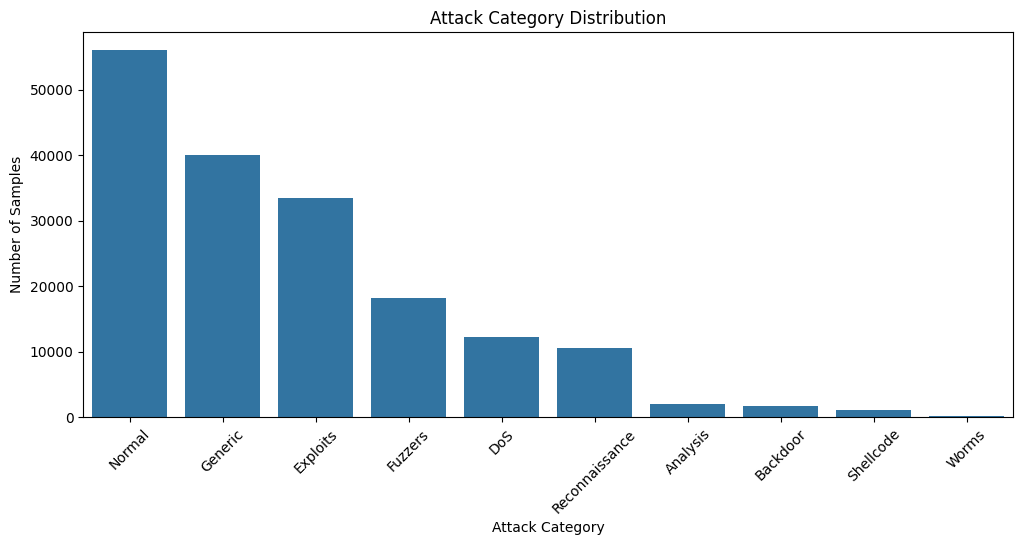

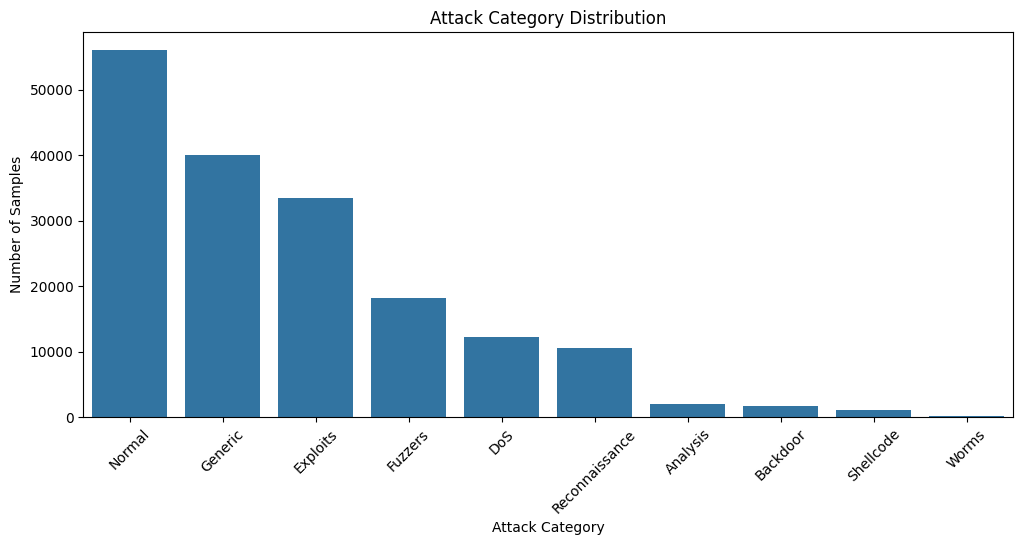

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check attack category distribution
print("Attack Category Distribution:")
print(df['attack_cat'].value_counts())

# Percentage distribution
print("\nPercentage Distribution:")
print(df['attack_cat'].value_counts(normalize=True) * 100)

# Visualize distribution
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x='attack_cat',
    order=df['attack_cat'].value_counts().index
)

plt.title('Attack Category Distribution')
plt.xlabel('Attack Category')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Separate features and multiclass target

X_train_multi = X_train[selected_features].copy()
X_test_multi = X_test[selected_features].copy()

y_train_multi = y_train['attack_cat'].copy()
y_test_multi = y_test['attack_cat'].copy()

print("Training shape:", X_train_multi.shape)
print("Testing shape:", X_test_multi.shape)

print("\nTraining class distribution:")
print(y_train_multi.value_counts())

print("\nTesting class distribution:")
print(y_test_multi.value_counts())

In [ ]:
import joblib
import numpy as np

preprocessor = joblib.load('preprocessor.pkl')

categorical_features = preprocessor['categorical_features']
numerical_features = preprocessor['numerical_features']
encoder = preprocessor['encoder']
scaler = preprocessor['scaler']

# Transform numerical features
X_train_multi_scaled = scaler.transform(
    X_train_multi[numerical_features]
)

X_test_multi_scaled = scaler.transform(
    X_test_multi[numerical_features]
)

# Transform categorical features
X_train_multi_encoded = encoder.transform(
    X_train_multi[categorical_features]
)

X_test_multi_encoded = encoder.transform(
    X_test_multi[categorical_features]
)

# Combine features
X_train_multi_processed = np.hstack([
    X_train_multi_scaled,
    X_train_multi_encoded.toarray()
])

X_test_multi_processed = np.hstack([
    X_test_multi_scaled,
    X_test_multi_encoded.toarray()
])

print("Processed training shape:", X_train_multi_processed.shape)
print("Processed testing shape:", X_test_multi_processed.shape)

Processed training shape: (140272, 167)
Processed testing shape: (35069, 167)
Processed training shape: (140272, 167)
Processed testing shape: (35069, 167)
Processed training shape: (140272, 167)
Processed testing shape: (35069, 167)


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd

# Calculate sample weights for each training sample
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_multi
)

# Display class weights
class_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_multi
)

weight_summary = pd.DataFrame({
    'Attack Category': y_train_multi.values,
    'Weight': class_weights
}).groupby('Attack Category')['Weight'].first().reset_index()

print("Class Weights:")
print(weight_summary)

Class Weights:
  Attack Category      Weight
0        Analysis    8.889227
1        Backdoor    9.795531
2             DoS    1.434127
3        Exploits    0.523208
4         Fuzzers    0.966726
5         Generic    0.438419
6          Normal    0.313107
7  Reconnaissance    1.678698
8       Shellcode   15.448458
9           Worms  137.521569
Class Weights:
  Attack Category      Weight
0        Analysis    8.889227
1        Backdoor    9.795531
2             DoS    1.434127
3        Exploits    0.523208
4         Fuzzers    0.966726
5         Generic    0.438419
6          Normal    0.313107
7  Reconnaissance    1.678698
8       Shellcode   15.448458
9           Worms  137.521569
Class Weights:
  Attack Category      Weight
0        Analysis    8.889227
1        Backdoor    9.795531
2             DoS    1.434127
3        Exploits    0.523208
4         Fuzzers    0.966726
5         Generic    0.438419
6          Normal    0.313107
7  Reconnaissance    1.678698
8       Shellcode   15.44

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_multi_encoded = label_encoder.fit_transform(y_train_multi)
y_test_multi_encoded = label_encoder.transform(y_test_multi)

print("Class Mapping:")

for index, category in enumerate(label_encoder.classes_):
    print(index, ":", category)

In [ ]:
from xgboost import XGBClassifier

xgb_multi_unweighted = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=10,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train without class weights
xgb_multi_unweighted.fit(
    X_train_multi_processed,
    y_train_multi_encoded
)

print("Unweighted Multiclass XGBoost training completed!")

Unweighted Multiclass XGBoost training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
y_pred_multi = xgb_multi_unweighted.predict(
    X_test_multi_processed
)

# Evaluation metrics
print("UNWEIGHTED XGBOOST - MODEL 2")
print("-" * 45)

print(f"Accuracy  : {accuracy_score(y_test_multi_encoded, y_pred_multi):.4f}")

print(f"Precision : {precision_score(y_test_multi_encoded, y_pred_multi, average='weighted', zero_division=0):.4f}")

print(f"Recall    : {recall_score(y_test_multi_encoded, y_pred_multi, average='weighted', zero_division=0):.4f}")

print(f"F1 Score  : {f1_score(y_test_multi_encoded, y_pred_multi, average='weighted', zero_division=0):.4f}")

# Classification report
print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(classification_report(
    y_test_multi_encoded,
    y_pred_multi,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

UNWEIGHTED XGBOOST - MODEL 2
---------------------------------------------
Accuracy  : 0.8279
Precision : 0.8416
Recall    : 0.8279
F1 Score  : 0.8033

CLASSIFICATION REPORT
---------------------------------------------
                precision    recall  f1-score   support

      Analysis       0.57      0.09      0.16       422
      Backdoor       0.90      0.12      0.21       314
           DoS       0.67      0.05      0.09      2483
      Exploits       0.61      0.95      0.74      6583
       Fuzzers       0.74      0.73      0.74      3674
       Generic       1.00      0.98      0.99      8005
        Normal       0.93      0.91      0.92     11200
Reconnaissance       0.93      0.75      0.83      2135
     Shellcode       0.63      0.83      0.72       225
         Worms       0.62      0.75      0.68        28

      accuracy                           0.83     35069
     macro avg       0.76      0.62      0.61     35069
  weighted avg       0.84      0.83      0.80     

In [ ]:
from xgboost import XGBClassifier

xgb_multi_weighted = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=10,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_multi_weighted.fit(
    X_train_multi_processed,
    y_train_multi_encoded,
    sample_weight=sample_weights
)

print("Weighted Multiclass XGBoost training completed!")

Weighted Multiclass XGBoost training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
y_pred_multi_weighted = xgb_multi_weighted.predict(
    X_test_multi_processed
)

# Evaluation metrics
print("WEIGHTED XGBOOST - MODEL 2")
print("-" * 45)

print(f"Accuracy  : {accuracy_score(y_test_multi_encoded, y_pred_multi_weighted):.4f}")

print(f"Precision : {precision_score(y_test_multi_encoded, y_pred_multi_weighted, average='weighted', zero_division=0):.4f}")

print(f"Recall    : {recall_score(y_test_multi_encoded, y_pred_multi_weighted, average='weighted', zero_division=0):.4f}")

print(f"F1 Score  : {f1_score(y_test_multi_encoded, y_pred_multi_weighted, average='weighted', zero_division=0):.4f}")

print(f"Macro F1  : {f1_score(y_test_multi_encoded, y_pred_multi_weighted, average='macro', zero_division=0):.4f}")

# Classification report
print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(classification_report(
    y_test_multi_encoded,
    y_pred_multi_weighted,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

WEIGHTED XGBOOST - MODEL 2
---------------------------------------------
Accuracy  : 0.7555
Precision : 0.8576
Recall    : 0.7555
F1 Score  : 0.7880
Macro F1  : 0.5777

CLASSIFICATION REPORT
---------------------------------------------
                precision    recall  f1-score   support

      Analysis       0.10      0.35      0.15       422
      Backdoor       0.05      0.43      0.09       314
           DoS       0.35      0.34      0.34      2483
      Exploits       0.88      0.49      0.63      6583
       Fuzzers       0.63      0.88      0.73      3674
       Generic       1.00      0.98      0.99      8005
        Normal       1.00      0.81      0.89     11200
Reconnaissance       0.84      0.80      0.82      2135
     Shellcode       0.43      0.96      0.59       225
         Worms       0.36      1.00      0.53        28

      accuracy                           0.76     35069
     macro avg       0.56      0.70      0.58     35069
  weighted avg       0.86      0.

In [ ]:
import numpy as np
from xgboost import XGBClassifier

# Moderate class weights using square root
moderate_weights = np.sqrt(sample_weights)

xgb_multi_moderate = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=10,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_multi_moderate.fit(
    X_train_multi_processed,
    y_train_multi_encoded,
    sample_weight=moderate_weights
)

print("Moderately Weighted XGBoost training completed!")

Moderately Weighted XGBoost training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
y_pred_multi_moderate = xgb_multi_moderate.predict(
    X_test_multi_processed
)

# Evaluation metrics
print("MODERATELY WEIGHTED XGBOOST - MODEL 2")
print(f"Accuracy  : {accuracy_score(y_test_multi_encoded, y_pred_multi_moderate):.4f}")
print(f"Precision : {precision_score(y_test_multi_encoded, y_pred_multi_moderate, average='weighted', zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test_multi_encoded, y_pred_multi_moderate, average='weighted', zero_division=0):.4f}")
print(f"F1 Score  : {f1_score(y_test_multi_encoded, y_pred_multi_moderate, average='weighted', zero_division=0):.4f}")
print(f"Macro F1  : {f1_score(y_test_multi_encoded, y_pred_multi_moderate, average='macro', zero_division=0):.4f}")
# Classification report
print("\nCLASSIFICATION REPORT")
print("-" * 50)

print(classification_report(
    y_test_multi_encoded,
    y_pred_multi_moderate,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test_multi_encoded,
    y_pred_multi_moderate,
    labels=range(len(label_encoder.classes_))
)

MODERATELY WEIGHTED XGBOOST - MODEL 2
Accuracy  : 0.8055
Precision : 0.8556
Recall    : 0.8055
F1 Score  : 0.8163
Macro F1  : 0.6442

CLASSIFICATION REPORT
--------------------------------------------------
                precision    recall  f1-score   support

      Analysis       0.33      0.23      0.27       422
      Backdoor       0.73      0.14      0.23       314
           DoS       0.35      0.77      0.49      2483
      Exploits       0.81      0.58      0.67      6583
       Fuzzers       0.67      0.85      0.75      3674
       Generic       1.00      0.98      0.99      8005
        Normal       0.98      0.85      0.91     11200
Reconnaissance       0.88      0.78      0.83      2135
     Shellcode       0.50      0.94      0.65       225
         Worms       0.53      0.86      0.66        28

      accuracy                           0.81     35069
     macro avg       0.68      0.70      0.64     35069
  weighted avg       0.86      0.81      0.82     35069



In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Base XGBoost model
xgb_base = XGBClassifier(
    objective='multi:softprob',
    num_class=10,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_grid = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [1, 2, 5, 10]
}

# Randomized Search
random_search_multi = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=10,
    scoring='f1_macro',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=1
)

# Train using moderate sample weights
random_search_multi.fit(
    X_train_multi_processed,
    y_train_multi_encoded,
    sample_weight=moderate_weights
)

print("\nTUNING COMPLETED")
print("Best Parameters:")
print(random_search_multi.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search_multi.best_score_)

In [ ]:
xgb_multi_tuned = random_search_multi.best_estimator_

y_pred_multi_tuned = xgb_multi_tuned.predict(
    X_test_multi_processed
)

print("TUNED MULTICLASS XGBOOST - MODEL 2")
print("-" * 50)

print(f"Accuracy  : {accuracy_score(y_test_multi_encoded, y_pred_multi_tuned):.4f}")

print(f"Precision : {precision_score(y_test_multi_encoded, y_pred_multi_tuned, average='weighted', zero_division=0):.4f}")

print(f"Recall    : {recall_score(y_test_multi_encoded, y_pred_multi_tuned, average='weighted', zero_division=0):.4f}")

print(f"F1 Score  : {f1_score(y_test_multi_encoded, y_pred_multi_tuned, average='weighted', zero_division=0):.4f}")

print(f"Macro F1  : {f1_score(y_test_multi_encoded, y_pred_multi_tuned, average='macro', zero_division=0):.4f}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test_multi_encoded,
    y_pred_multi_tuned,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

In [ ]:
import joblib

joblib.dump(
    xgb_multi_tuned,
    'xgboost_multiclass_tuned_model.pkl'
)

print("Tuned multiclass model saved successfully!")

In [ ]:
from google.colab import files

files.download('xgboost_multiclass_tuned_model.pkl')

In [ ]:
import joblib
from google.colab import files

joblib.dump(label_encoder, 'label_encoder.pkl')

files.download('label_encoder.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib

preprocessor = joblib.load('preprocessor.pkl')

print("Selected Features:")
for i, feature in enumerate(preprocessor['selected_features'], 1):
    print(i, feature)

print("\nCategorical Features:")
print(preprocessor['categorical_features'])

print("\nNumerical Features:")
print(preprocessor['numerical_features'])

Selected Features:
1 sttl
2 ct_srv_dst
3 sbytes
4 proto
5 service
6 ct_dst_sport_ltm
7 state
8 smean
9 sloss
10 dpkts
11 ct_dst_src_ltm
12 dmean
13 swin
14 synack
15 ct_srv_src
16 dbytes
17 ct_state_ttl

Categorical Features:
['proto', 'service', 'state']

Numerical Features:
['sttl', 'ct_srv_dst', 'sbytes', 'ct_dst_sport_ltm', 'smean', 'sloss', 'dpkts', 'ct_dst_src_ltm', 'dmean', 'swin', 'synack', 'ct_srv_src', 'dbytes', 'ct_state_ttl']


In [ ]:
import xgboost
import sklearn
import numpy
import joblib
import pandas

print("XGBoost version :", xgboost.__version__)
print("Scikit-learn version :", sklearn.__version__)
print("NumPy version :", numpy.__version__)
print("Joblib version :", joblib.__version__)
print("Pandas version :", pandas.__version__)

XGBoost version : 3.4.1
Scikit-learn version : 1.6.1
NumPy version : 2.4.6
Joblib version : 1.6.0
Pandas version : 2.2.3


In [ ]:
import xgboost as xgb

for name, obj in list(globals().items()):
    if isinstance(obj, xgb.XGBClassifier):
        print(name, type(obj))


__ <class 'xgboost.sklearn.XGBClassifier'>
fs_model <class 'xgboost.sklearn.XGBClassifier'>
_56 <class 'xgboost.sklearn.XGBClassifier'>
xgb_model <class 'xgboost.sklearn.XGBClassifier'>
xgb_base <class 'xgboost.sklearn.XGBClassifier'>
xgb_tuned <class 'xgboost.sklearn.XGBClassifier'>
xgb_multi_unweighted <class 'xgboost.sklearn.XGBClassifier'>
xgb_multi_weighted <class 'xgboost.sklearn.XGBClassifier'>
xgb_multi_moderate <class 'xgboost.sklearn.XGBClassifier'>


In [ ]:
import os

os.makedirs("flask_models", exist_ok=True)

# Export binary model
xgb_tuned.save_model(
    "flask_models/xgboost_tuned_model.json"
)

# Export multiclass model
xgb_multi_moderate.save_model(
    "flask_models/xgboost_multiclass_tuned_model.json"
)

print("Both models exported successfully!")

Both models exported successfully!


In [ ]:
from google.colab import files

files.download("flask_models/xgboost_tuned_model.json")
files.download("flask_models/xgboost_multiclass_tuned_model.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>